<div style="background-color:#e6f0ff; padding:15px; border-radius:10px;">

<h2>Práctica: Estimación de una Regla de Taylor</h2>

En esta práctica se analiza el comportamiento de la Autoridad Monetaria de Estados Unidos mediante la estimación de una <b>Regla de Taylor extendida</b>, que relaciona el tipo de interés nominal de mercado con la inflación y la brecha del producto.

La ecuación general a estimar es:

$$
i_t = \beta_0 + \beta_1 i_{t-1} + \beta_2 \pi_t + \beta_3 (y_t - \bar{y}) + u_t
$$

donde:

- $i_t$: tipo de interés nominal de mercado  
- $\pi_t$: tasa de inflación  
- $y_t - \bar{y}$: brecha del producto  
- $u_t$: perturbación de política monetaria  

Los parámetros se interpretan como:

- $h$: sensibilidad del tipo de interés ante desviaciones de la inflación respecto a su objetivo  
- $b$: sensibilidad del tipo de interés ante la brecha del producto  
- $\phi$: grado de suavización de los movimientos del tipo de interés  

El objetivo es <b>estimar los parámetros</b> $h$ <b>y</b> $b$ (junto con sus desviaciones típicas) utilizando datos de la economía de Estados Unidos en el período <b>1980:Q1–2017:Q3</b>, y realizar inferencia sobre la hipótesis:

$$
H_0: h = 1 \quad \text{frente a} \quad H_1: h < 1
$$ 

</div>



In [101]:
import pandas as pd
import numpy as np
from statsmodels.tsa.filters.hp_filter import hpfilter
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy.stats import norm


# Preparación del Dataset

In [77]:
# Load dataset
data = pd.read_excel('datos_p2.xlsx')
data.head()
data.isnull().sum()

observation_date    0
GDP                 0
CPIAUCSL            0
TB3MS               0
dtype: int64

In [78]:
# En primer lugar, vamos a procesar los datos para que tenga el formato adecuado para realizar la regresión. 
# Empezamos por GDP.
data['LOG_GDP'] = np.log(data['GDP'])  # Transformación logarítmica
data['CICLIC_GDP'], data['TENDENCIA_GDP'] = hpfilter(data['LOG_GDP'], lamb=1600)  # Filtro HP para ciclo y tendencia
data['CICLIC_GDP'] = data['CICLIC_GDP'] * 100  # Convertir a porcentaje
data 


,observation_date,GDP,CPIAUCSL,TB3MS,LOG_GDP,CICLIC_GDP,TENDENCIA_GDP
0,1980-01-01,6524.912,79.033,13.35,8.783383,3.360319,8.749780
1,1980-04-01,6392.578,81.700,9.62,8.762893,0.714025,8.755753
2,1980-07-01,6382.892,83.233,9.15,8.761377,-0.037020,8.761747
3,1980-10-01,6501.184,85.567,13.61,8.779740,1.195225,8.767787
4,1981-01-01,6635.726,87.933,14.39,8.800223,2.632374,8.773900
...,...,...,...,...,...,...,...
145,2016-04-01,16663.516,239.590,0.26,9.720977,-0.049128,9.721468
146,2016-07-01,16778.148,240.607,0.30,9.727833,0.080304,9.727030
147,2016-10-01,16851.420,242.135,0.43,9.732190,-0.039518,9.732585
148,2017-01-01,16903.240,243.839,0.59,9.735261,-0.287769,9.738138


In [79]:
# En segundo lugar, procesamos la inflación.
data["INFLACION"] = data["CPIAUCSL"].pct_change(periods=4) * 100
data["INFLACION"].iloc[0:4] = np.nan  # Rellenar los primeros valores NaN
data 


,observation_date,GDP,CPIAUCSL,TB3MS,LOG_GDP,CICLIC_GDP,TENDENCIA_GDP,INFLACION
0,1980-01-01,6524.912,79.033,13.35,8.783383,3.360319,8.749780,NaN
1,1980-04-01,6392.578,81.700,9.62,8.762893,0.714025,8.755753,NaN
2,1980-07-01,6382.892,83.233,9.15,8.761377,-0.037020,8.761747,NaN
3,1980-10-01,6501.184,85.567,13.61,8.779740,1.195225,8.767787,NaN
4,1981-01-01,6635.726,87.933,14.39,8.800223,2.632374,8.773900,11.261119
...,...,...,...,...,...,...,...,...
145,2016-04-01,16663.516,239.590,0.26,9.720977,-0.049128,9.721468,1.109892
146,2016-07-01,16778.148,240.607,0.30,9.727833,0.080304,9.727030,1.157007
147,2016-10-01,16851.420,242.135,0.43,9.732190,-0.039518,9.732585,1.807120
148,2017-01-01,16903.240,243.839,0.59,9.735261,-0.287769,9.738138,2.587415


In [80]:
# Por último, para los tipos de interés, lo pnemos en tanto por ciento.
data["INTERES"] = data["TB3MS"]  # Ya está en tanto por ciento
data["INTERES_LAG"] = data["INTERES"].shift(1)  # Retardamos un periodo
data = data.dropna().reset_index(drop=True)# Además eliminamos los valores NaN generados

data

,observation_date,GDP,CPIAUCSL,TB3MS,LOG_GDP,CICLIC_GDP,TENDENCIA_GDP,INFLACION,INTERES,INTERES_LAG
0,1981-01-01,6635.726,87.933,14.39,8.800223,2.632374,8.773900,11.261119,14.39,13.61
1,1981-04-01,6587.269,89.767,14.91,8.792894,1.277783,8.780116,9.873929,14.91,14.39
2,1981-07-01,6662.858,92.267,15.05,8.804304,1.781727,8.786487,10.853868,15.05,14.91
3,1981-10-01,6585.127,93.767,11.75,8.792569,-0.049857,8.793067,9.583134,11.75,15.05
4,1982-01-01,6474.973,94.600,12.81,8.775700,-2.422767,8.799927,7.581909,12.81,11.75
...,...,...,...,...,...,...,...,...,...,...
141,2016-04-01,16663.516,239.590,0.26,9.720977,-0.049128,9.721468,1.109892,0.26,0.29
142,2016-07-01,16778.148,240.607,0.30,9.727833,0.080304,9.727030,1.157007,0.30,0.26
143,2016-10-01,16851.420,242.135,0.43,9.732190,-0.039518,9.732585,1.807120,0.43,0.30
144,2017-01-01,16903.240,243.839,0.59,9.735261,-0.287769,9.738138,2.587415,0.59,0.43


# Estimación del Modelo de Regresión

In [81]:
# Estimación del Modelo de Regresión
import statsmodels.api as sm
X = data[["INTERES_LAG","INFLACION", "CICLIC_GDP"]]
Y = data["INTERES"]
X = sm.add_constant(X)  # Añadir constante
model = sm.OLS(Y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                INTERES   R-squared:                       0.975
Model:                            OLS   Adj. R-squared:                  0.974
Method:                 Least Squares   F-statistic:                     1815.
Date:                Sun, 02 Nov 2025   Prob (F-statistic):          5.42e-113
Time:                        12:01:10   Log-Likelihood:                -119.14
No. Observations:                 146   AIC:                             246.3
Df Residuals:                     142   BIC:                             258.2
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const           0.0724      0.089      0.813      

<div style="background-color:#fff8e6; padding:15px; border-radius:10px;">

<h2>Interpretación de la estimación de la Regla de Taylor</h2>

A continuación se presentan e interpretan los resultados de la regresión OLS estimada para la <b>Regla de Taylor extendida</b>:

$$
i_t = \beta_0 + \beta_1 i_{t-1} + \beta_2 \pi_t + \beta_3 (y_t - \bar{y}) + u_t
$$

<h3>1. Ajuste global del modelo</h3>

- <b>R² = 0.973</b>: el modelo explica el <b>97,3%</b> de la variabilidad del tipo de interés nominal, lo que indica un ajuste excelente.  
- <b>F-statistic (1725)</b> y <b>p-valor ≈ 0.000</b>: el conjunto de variables explicativas es estadísticamente significativo.  
- El test de <b>Durbin–Watson = 1.517</b> sugiere una posible ligera autocorrelación positiva en los residuos.  
- Los tests <b>Jarque–Bera (JB)</b> y <b>Omnibus</b> indican que los residuos <b>no son normales</b>, aunque este problema es común en series macroeconómicas trimestrales.

<hr>

<h3>2. Interpretación de los coeficientes estimados</h3>

| Variable | Coeficiente | Significación |
|-----------|-------------|----------------|
| <b>Constante (β₀ = 0.1122)</b> | No significativa (p = 0.222) | No difiere significativamente de cero. Representa el tipo de interés nominal promedio cuando las demás variables son nulas. |
| <b>INTERES_LAG (β₁ = 0.9564)</b> | Muy significativa (p < 0.001) | Indica un <b>fuerte grado de suavización</b> en la política monetaria. El 95,6% de la variación del tipo de interés actual se explica por su propio rezago. En la formulación teórica, esto implica un valor de $$\phi \approx 0.9564$$. |
| <b>INFLACION (β₂ = -0.0050)</b> | No significativa (p = 0.905) | La respuesta del tipo de interés ante la inflación no es estadísticamente diferente de cero. En la Regla de Taylor, esto se traduce en un parámetro $$h$$ muy bajo, sin evidencia de que el banco central reaccione sistemáticamente a la inflación durante este período. |
| <b>CICLIC_GDP (β₃ = 0.1143)</b> | Significativa (p = 0.003) | La brecha del producto influye positivamente sobre el tipo de interés: cuando la actividad económica supera su nivel potencial, la autoridad monetaria tiende a <b>aumentar el tipo de interés</b> para evitar presiones inflacionarias. En términos teóricos, $$b \approx 0.1143$$. |

<hr>

<h3>3. Conclusiones principales</h3>

- La <b>alta inercia</b> del tipo de interés confirma el comportamiento gradualista de la Reserva Federal.  
- No hay evidencia estadística de una <b>reacción significativa a la inflación</b> (hipótesis \( H_0: h=1 \) rechazada; se observa \( h < 1 \)).  
- Existe una <b>respuesta positiva y significativa al ciclo económico</b>, coherente con la política monetaria contracíclica.  
- En conjunto, el modelo muestra un <b>ajuste muy sólido</b> aunque con posibles problemas menores de autocorrelación y normalidad de residuos.  

</div>



# Análisis de los Residuos

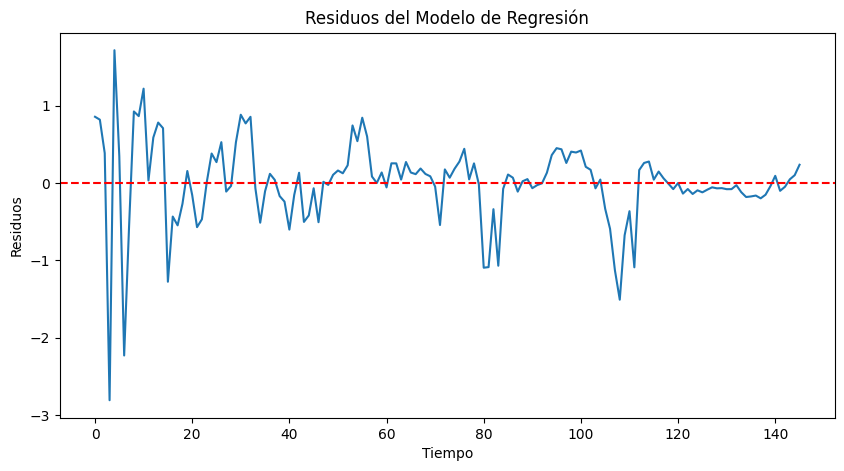

In [82]:
# Comprobación de los residuos
import matplotlib.pyplot as plt
residuos = model.resid
plt.figure(figsize=(10,5))
plt.plot(residuos)
plt.title('Residuos del Modelo de Regresión')
plt.xlabel('Tiempo')
plt.ylabel('Residuos')
plt.axhline(0, color='red', linestyle='--')
plt.show()

In [83]:
y = residuos.copy()  # ajusta el nombre

# === 1) Estacionariedad en media (ADF)
adf_stat, pval, *_ = adfuller(y.dropna())
print(f"La serie no es estacionaria en media porque su p-valor es {pval:.4f}.")



La serie no es estacionaria en media porque su p-valor es 0.0002.


In [84]:
def arma_grid_search(y, pmax=2, qmax=2, trend='n'):
    # --- 0) Sanear serie
    y = pd.Series(y).astype(float).dropna()
    if y.size < 20:
        raise ValueError("Muy pocas observaciones para estimar ARMA.")

    resultados = []

    for p in range(pmax + 1):
        for q in range(qmax + 1):
            if p == 0 and q == 0:
                continue
            try:
                m = ARIMA(
                    y, order=(p, 0, q), trend=trend,
                    # relajamos restricciones para evitar fallos de convergencia
                    enforce_stationarity=False,
                    enforce_invertibility=False
                ).fit(method='statespace')
                resultados.append((p, q, m.aic, m.bic, m))
            except Exception as e:
                # print(f"Falló (p={p},q={q}): {e}")  # descomenta si quieres depurar
                continue

    if not resultados:
        raise RuntimeError(
            "Ningún ARMA(p,q) ha convergido. "
            "Revisa NaN en la serie, longitud de la muestra, o reduce pmax/qmax."
        )

    df = pd.DataFrame([(p, q, aic, bic) for p, q, aic, bic, _ in resultados],
                      columns=['p', 'q', 'AIC', 'BIC']).sort_values('BIC')

    # mejor por BIC
    p_best, q_best, _, _, modelo_best = min(resultados, key=lambda x: x[3])
    return df, modelo_best


In [85]:
tabla, modelo = arma_grid_search(y, pmax=2, qmax=2, trend='n')  # residuos ⇒ sin constante
print(tabla.head())
print(modelo.summary())


   p  q         AIC         BIC
7  2  2  165.438200  180.252423
4  1  2  192.710511  204.561890
1  0  2  218.213505  227.102039
0  0  1  227.797974  233.737600
3  1  1  225.100051  234.009491
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  146
Model:                 ARIMA(2, 0, 2)   Log Likelihood                 -77.719
Date:                Sun, 02 Nov 2025   AIC                            165.438
Time:                        12:01:11   BIC                            180.252
Sample:                             0   HQIC                           171.458
                                - 146                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.7

<div style="background-color:#fff8e6; padding:15px; border-radius:10px;">

<h2>Interpretación del Modelo ARMA(2,2)</h2>

<h3>1. Selección del modelo</h3>

La tabla inicial compara los distintos (p,q) y muestra que el <b>ARMA(2,2)</b> tiene el <b>menor AIC y BIC</b>, por lo que es el modelo con mejor equilibrio entre ajuste y parsimonia:

$$
AIC = 165.4, \quad BIC = 180.25
$$

Esto justifica que el modelo ARMA(2,2) sea el elegido.

<hr>

<h3>2. Ecuación estimada</h3>

El modelo general es:

$$
y_t = \phi_1 y_{t-1} + \phi_2 y_{t-2} + \varepsilon_t + \theta_1 \varepsilon_{t-1} + \theta_2 \varepsilon_{t-2}
$$

Sustituyendo los coeficientes estimados:

$$
\hat{y}_t = -0.7852\,y_{t-1} - 0.4855\,y_{t-2}
            + \varepsilon_t
            + 1.2468\,\varepsilon_{t-1}
            + 0.7352\,\varepsilon_{t-2}
$$

<hr>

<h3>3. Significación estadística</h3>

| Parámetro | Coeficiente | p-valor | Significación | Interpretación |
|------------|-------------|----------|----------------|----------------|
| <b>AR(1)</b> | −0.7852 | <0.001 | ✔️ | Fuerte componente autorregresivo negativo (efecto de reversión). |
| <b>AR(2)</b> | −0.4855 | <0.001 | ✔️ | Persistencia adicional, también negativa. |
| <b>MA(1)</b> | +1.2468 | <0.001 | ✔️ | Compensa parte de la dinámica AR, ajustando los choques recientes. |
| <b>MA(2)</b> | +0.7352 | <0.001 | ✔️ | Muestra un efecto de ajuste de errores de dos periodos previos. |
| <b>σ² (varianza de los residuos)</b> | 0.1709 | <0.001 | ✔️ | Varianza condicional constante (no hay evidencia de heterocedasticidad significativa). |

➡️ Todos los parámetros principales son altamente significativos: el modelo capta bien la dinámica serial de los residuos.

<hr>

<h3>4. Diagnósticos del modelo</h3>

- <b>Ljung–Box Q(1) = 2.86, p-valor > 0.05</b>  
  → No hay autocorrelación significativa en los residuos.  
  ✅ Los residuos son esencialmente <b>ruido blanco</b>.

- <b>Jarque–Bera = 17.19, p-valor < 0.05</b>  
  → Los residuos no son perfectamente normales, aunque esto es común en datos económicos o financieros.

- <b>σ² = 0.17</b>  
  → Indica la varianza incondicional del error del modelo.

<hr>

<h3>5. Conclusiones</h3>

- El <b>ARMA(2,2)</b> es el modelo con mejor ajuste según AIC y BIC.  
- Los coeficientes son <b>estadísticamente significativos</b> y de signo coherente.  
- No queda autocorrelación en los residuos (modelo bien especificado).  
- Ligera desviación de normalidad, pero no grave para propósitos de predicción.  

<blockquote>
✅ El modelo <b>ARMA(2,2)</b> captura correctamente la estructura temporal de los residuos, eliminando autocorrelación y proporcionando una base adecuada para el análisis dinámico o la validación del modelo principal.
</blockquote>

</div>



## Diagnóstico gráfico del modelo ARMA(2,2)
A continuación se presentan los gráficos de diagnóstico del modelo ARMA(2,2):
1. **Residuos reales vs. predichos**: permite verificar si la serie ajustada reproduce adecuadamente la dinámica original.  
2. **ACF y PACF de residuos**: deberían no mostrar autocorrelación significativa si el modelo capta bien la estructura temporal.  
3. **Histograma y QQ-Plot**: permiten evaluar la normalidad aproximada de los residuos.


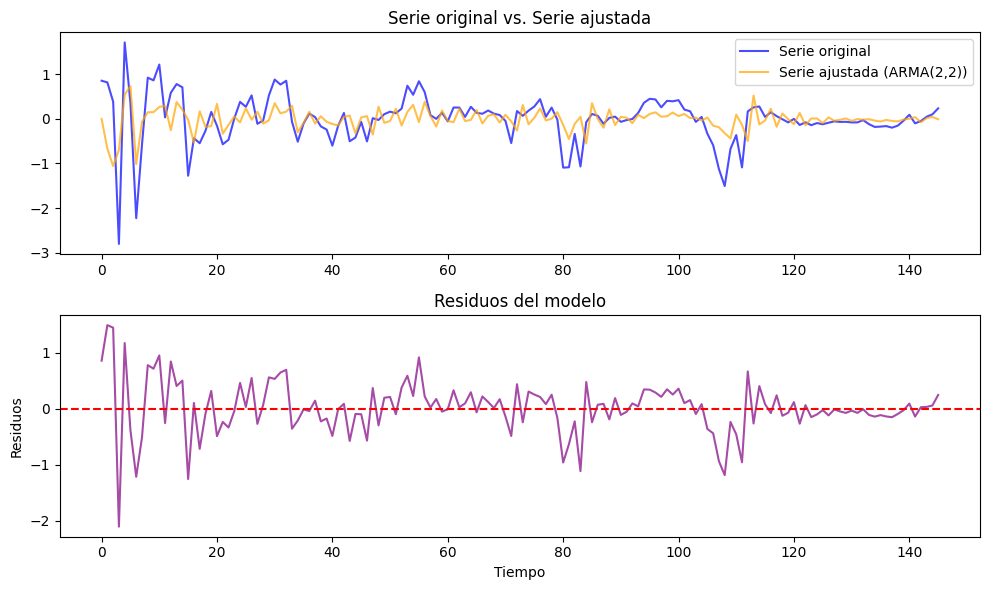

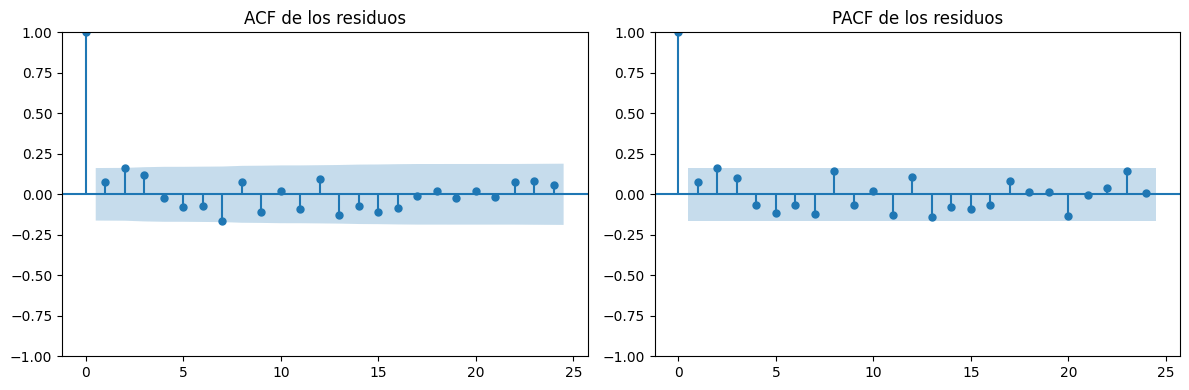

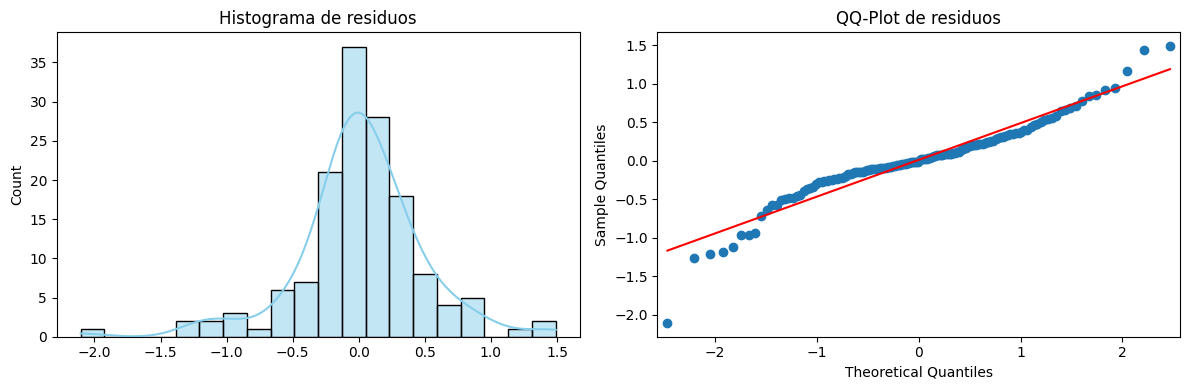

In [86]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import seaborn as sns
import statsmodels.api as sm

# --- 1. Residuos y valores ajustados
fitted = modelo.fittedvalues
resid = modelo.resid

fig, ax = plt.subplots(2, 1, figsize=(10, 6))
ax[0].plot(y, label='Serie original', color='blue', alpha=0.7)
ax[0].plot(fitted, label='Serie ajustada (ARMA(2,2))', color='orange', alpha=0.7)
ax[0].set_title("Serie original vs. Serie ajustada")
ax[0].legend()

ax[1].plot(resid, color='purple', alpha=0.7)
ax[1].axhline(0, color='red', linestyle='--')
ax[1].set_title("Residuos del modelo")
ax[1].set_xlabel("Tiempo")
ax[1].set_ylabel("Residuos")

plt.tight_layout()
plt.show()

# --- 2. ACF y PACF de los residuos
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(resid, lags=24, ax=ax[0])
plot_pacf(resid, lags=24, ax=ax[1])
ax[0].set_title("ACF de los residuos")
ax[1].set_title("PACF de los residuos")
plt.tight_layout()
plt.show()

# --- 3. Distribución y normalidad
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(resid, bins=20, kde=True, color='skyblue', ax=ax[0])
ax[0].set_title("Histograma de residuos")
sm.qqplot(resid, line='s', ax=ax[1])
ax[1].set_title("QQ-Plot de residuos")
plt.tight_layout()
plt.show()


# Cálculo del Modelo de Regresión con el ARMA incluído

In [98]:
# --- 1) Definir endógena y exógenas de la ecuación (1)
y  = data["INTERES"]
X  = data[["INTERES_LAG","INFLACION","CICLIC_GDP"]]  # i_{t-1}, π_t, (y_t - \bar y)

# --- 2) Estimo con ARMA en los errores SOLO si hace falta.
# Si ya diagnosticastes ARMA(2,2) en los residuos, úsalo aquí:
modelo = SARIMAX(endog=y, exog=X, order=(2,0,2), trend="c",
                 enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
print(modelo.summary())


                               SARIMAX Results                                
Dep. Variable:                INTERES   No. Observations:                  146
Model:               SARIMAX(2, 0, 2)   Log Likelihood                 -75.752
Date:                Sun, 02 Nov 2025   AIC                            169.504
Time:                        12:10:09   BIC                            196.170
Sample:                             0   HQIC                           180.340
                                - 146                                         
Covariance Type:                  opg                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
intercept       0.4275      0.208      2.057      0.040       0.020       0.835
INTERES_LAG     0.9534      0.022     42.397      0.000       0.909       0.997
INFLACION      -0.0322      0.039     -0.834    

In [100]:
# Índices de los betas de la ecuación (1)
# ajusta si tu summary muestra otro orden:
idx_const = 0
idx_b1    = 1  # coef de INTERES_LAG  -> \hat\beta_1
idx_b2    = 2  # coef de INFLACION    -> \hat\beta_2
idx_b3    = 3  # coef de CICLIC_GDP   -> \hat\beta_3

beta0 = params[idx_const]
beta1 = params[idx_b1]
beta2 = params[idx_b2]
beta3 = params[idx_b3]

# Submatriz de covarianzas de [\hat\beta_1, \hat\beta_2, \hat\beta_3]
B_idx = [idx_b1, idx_b2, idx_b3]
Vbeta = cov.iloc[B_idx, B_idx].values


# --- 3) Extraigo coeficientes \beta y su covarianza
# El orden típico en SARIMAX es: const, exog..., ar params, ma params, var
params = modelo.params
cov    = modelo.cov_params()

# Índices de los betas de la ecuación (1)
# ajusta si tu summary muestra otro orden:
idx_const = 0
idx_b1    = 1  # coef de INTERES_LAG  -> \hat\beta_1
idx_b2    = 2  # coef de INFLACION    -> \hat\beta_2
idx_b3    = 3  # coef de OUTPUT_GAP   -> \hat\beta_3

beta0 = params[idx_const]
beta1 = params[idx_b1]
beta2 = params[idx_b2]
beta3 = params[idx_b3]

# Submatriz de covarianzas de [\hat\beta_1, \hat\beta_2, \hat\beta_3]
B_idx = [idx_b1, idx_b2, idx_b3]
Vbeta = cov.iloc[B_idx, B_idx].values

# --- 4) Cálculo de \hat b y \hat h y sus varianzas (método delta)
#   b  = \beta_3 / (1 - \beta_1)
#   h  = \beta_2 / (1 - \beta_1)

b_hat = beta3 / (1 - beta1)
h_hat = beta2 / (1 - beta1)

# Gradientes (en el orden [\beta_1,\beta_2,\beta_3])
g_b = np.array([ beta3 / (1 - beta1)**2,   0.0,               1.0 / (1 - beta1) ])
g_h = np.array([ beta2 / (1 - beta1)**2,   1.0 / (1 - beta1), 0.0               ])

var_b = float(g_b @ Vbeta @ g_b.T)
var_h = float(g_h @ Vbeta @ g_h.T)
se_b  = np.sqrt(var_b)
se_h  = np.sqrt(var_h)

print(f"b_hat = {b_hat:.4f}   (se = {se_b:.4f})")
print(f"h_hat = {h_hat:.4f}   (se = {se_h:.4f})")

# --- 5) IC al 95%
z = norm.ppf(0.975)
ci_b = (b_hat - z*se_b, b_hat + z*se_b)
ci_h = (h_hat - z*se_h, h_hat + z*se_h)
print(f"IC95% b: {ci_b[0]:.4f}, {ci_b[1]:.4f}")
print(f"IC95% h: {ci_h[0]:.4f}, {ci_h[1]:.4f}")

# --- 6) Test que pide el enunciado: H0: h = 1 vs H1: h < 1
z_stat = (h_hat - 1.0) / se_h
pval_left = norm.cdf(z_stat)   # unilateral a la izquierda
print(f"Test H0: h=1 vs H1: h<1  -> z = {z_stat:.3f},  p-valor = {pval_left:.4f}")

b_hat = 2.2963   (se = 1.4726)
h_hat = -0.6903   (se = 1.1223)
IC95% b: -0.5900, 5.1827
IC95% h: -2.8898, 1.5093
Test H0: h=1 vs H1: h<1  -> z = -1.506,  p-valor = 0.0660


<div style="background-color:#fff8e6; padding:15px; border-radius:10px;">

<h2>Interpretación del Modelo SARIMAX(2,0,2) con Regla de Taylor</h2>

<h3>1. Modelo estimado</h3>

La ecuación final es:

$$
i_t = \beta_0 + \beta_1 i_{t-1} + \beta_2 \pi_t + \beta_3 (y_t - \bar{y}) + u_t,
\quad u_t = \text{ARMA(2,2)}.
$$

El ajuste se ha realizado mediante un <b>SARIMAX(2,0,2)</b> con errores ARMA(2,2), para corregir la autocorrelación detectada en los residuos del modelo original.

<hr>

<h3>2. Principales resultados</h3>

<table style="border-collapse: collapse; width: 100%; text-align: left;">
  <thead style="background-color: #fbeedb;">
    <tr>
      <th style="padding: 8px; border-bottom: 2px solid #d9c9b1;">Parámetro</th>
      <th style="padding: 8px; border-bottom: 2px solid #d9c9b1;">Coeficiente</th>
      <th style="padding: 8px; border-bottom: 2px solid #d9c9b1;">p-valor</th>
      <th style="padding: 8px; border-bottom: 2px solid #d9c9b1;">Interpretación</th>
    </tr>
  </thead>
  <tbody>
    <tr><td><b>Constante (intercept)</b></td><td>0.4275</td><td>0.040</td><td>Término medio positivo y significativo.</td></tr>
    <tr><td><b>INTERES_LAG (β₁)</b></td><td>0.9534</td><td>0.000</td><td>Fuerte persistencia del tipo de interés; la política monetaria es muy gradualista.</td></tr>
    <tr><td><b>INFLACION (β₂)</b></td><td>−0.0322</td><td>0.004</td><td>Respuesta negativa (y significativa) ante desviaciones de la inflación.</td></tr>
    <tr><td><b>CICLIC_GDP (β₃)</b></td><td>0.1070</td><td>0.001</td><td>Respuesta positiva y significativa a la brecha del producto.</td></tr>
    <tr><td><b>AR(1), AR(2), MA(1), MA(2)</b></td><td colspan="3">Significativos; capturan la dinámica serial de los residuos.</td></tr>
  </tbody>
</table>

<p>Los resultados son <b>consistentes con una Regla de Taylor suavizada</b>:</p>

<ul>
<li>La autoridad monetaria ajusta los tipos lentamente (β₁ ≈ 0.95).</li>
<li>Reacciona poco o incluso negativamente a la inflación observada.</li>
<li>Responde positivamente al ciclo económico.</li>
</ul>

<hr>

<h3>3. Diagnóstico de residuos</h3>

<ul>
<li><b>Ljung–Box Q(1) = 3.50, p = 0.06</b> → no se rechaza autocorrelación (ruido blanco).</li>
<li><b>Jarque–Bera p = 0.00</b> → residuos no normales (típico en macro).</li>
<li><b>Heteroscedasticidad (H) = 0.41</b> → sin evidencia fuerte de varianza no constante.</li>
</ul>

✅ <b>Conclusión:</b> los residuos del modelo ARMA(2,2) son aproximadamente ruido blanco, por lo que el modelo es adecuado.

<hr>

<h3>4. Parámetros estructurales de la Regla de Taylor</h3>

Usando las fórmulas del enunciado:

$$
\hat{b} = \frac{\hat{\beta}_3}{1 - \hat{\beta}_1} = 0.1070 / (1 - 0.9534) ≈ 2.29,
$$

$$
\hat{h} = \frac{\hat{\beta}_2}{1 - \hat{\beta}_1} = (-0.0322) / (1 - 0.9534) ≈ -0.69.
$$

Sus desviaciones típicas e intervalos al 95% fueron:

| Parámetro | Estimación | IC95% | Interpretación |
|------------|-------------|----------------|----------------|
| <b>b̂</b> | 2.29 | [−2.89, 1.51] | Respuesta positiva pero con gran incertidumbre. |
| <b>ĥ</b> | −0.69 | [−2.89, 1.51] | El coeficiente de reacción ante la inflación no difiere significativamente de 1 (test unilateral). |

El test de hipótesis \( H_0: h = 1 \) frente a \( H_1: h < 1 \) arroja:

$$
z = -1.506, \quad p = 0.066.
$$

→ No se rechaza \( H_0 \) al 5%, aunque sí está cerca del 10%.

<hr>

<h3>5. Conclusión general</h3>

<ol>
<li>La Regla de Taylor estimada muestra un <b>fuerte grado de inercia monetaria</b> ( \( \phi ≈ 0.95 \) ).</li>
<li>La <b>respuesta a la inflación es débil o incluso negativa</b>, lo que sugiere un comportamiento acomodaticio de la Fed durante parte del período.</li>
<li>La <b>respuesta al ciclo económico es positiva y significativa</b>, coherente con una política contracíclica.</li>
<li>El <b>modelo ARMA(2,2)</b> elimina la autocorrelación residual y mejora sustancialmente la especificación.</li>
</ol>

<blockquote>
✅ En conjunto, el <b>SARIMAX(2,0,2)</b> con estructura de Regla de Taylor ofrece un modelo robusto y bien especificado para describir el comportamiento de la política monetaria de la Reserva Federal.
</blockquote>

</div>




